# Classificação Supervisionada de Doenças Cardiovasculares na Coorte NHANES 2021–2023
**Disciplina:** FT108A – Introdução ao Aprendizado de Máquina (2s 2026) — Faculdade de Tecnologia (UNICAMP)

**Integrantes do Grupo:**
- Bruno Ricardo Corrêa (RA: 260759)
- Cristiane Brandão Cobo (RA: 288831)
- Gustavo Bilia Marques (RA: 279808)
- Julio Morino Anastácio (RA: 173434)
- Sabrina Tomaz Barbosa (RA: 324065)

---
Este notebook implementa o pipeline experimental para a disciplina **FT108A**, aplicando e comparando cinco algoritmos de aprendizado de máquina supervisionado (**Regressão Logística, KNN, Árvore de Decisão, Random Forest e XGBoost**) na classificação binária da presença/registro de doenças cardiovasculares (DCV) utilizando **20 variáveis preditoras** da coorte **NHANES 2021–2023**, com remoção de registros incompletos (`dropna`) e balanceamento de classes via reamostragem (**SMOTE** e **RandomUnderSampler**).

## 1. Instalação e Importação de Bibliotecas

In [1]:
# Instalação de pacotes necessários (caso não estejam presentes no ambiente)
# %pip install -q scikit-learn imbalanced-learn xgboost pandas numpy matplotlib seaborn scipy

In [2]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform, randint, uniform
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    fbeta_score,
    make_scorer,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

warnings.filterwarnings('ignore')
os.environ['LOKY_MAX_CPU_COUNT'] = '10'
os.makedirs('figuras', exist_ok=True)

# Semente global para reprodutibilidade
FIXED_RANDOM_STATE = 42

## 2. Carregamento dos Dados e Definição da Coorte
O questionário de condições médicas do NHANES (variáveis `MCQ160B` a `MCQ160F`) é aplicado apenas a adultos com **20 anos ou mais**. Além disso, participantes gestantes (`RIDEXPRG == 1`) são excluídas para evitar alterações fisiológicas transitórias nos biomarcadores e medidas antropométricas.

A variável alvo binária (`target`) indica a presença (`1`) ou ausência (`0`) de registro de qualquer uma das cinco condições cardiovasculares investigadas:
- `MCQ160B`: Insuficiência cardíaca congestiva (*Congestive heart failure*)
- `MCQ160C`: Doença arterial coronariana (*Coronary heart disease*)
- `MCQ160D`: Angina (*Angina pectoris*)
- `MCQ160E`: Infarto agudo do miocárdio (*Heart attack*)
- `MCQ160F`: Acidente vascular cerebral (*Stroke*)

In [3]:
# 1. Leitura da base consolidada NHANES 2021-2023
cvd_df = pd.read_csv('data/nhanes_2021_2023_merged_data.csv')
print(f"Total de participantes na base bruta: {len(cvd_df)}")

# 2. Filtro de adultos (>= 20 anos)
cvd_df = cvd_df[cvd_df['RIDAGEYR'] >= 20].copy()
print(f"Total após filtro de adultos (>= 20 anos): {len(cvd_df)}")

# 3. Construção da variável alvo binária (target)
target_cols = ['MCQ160B', 'MCQ160C', 'MCQ160D', 'MCQ160E', 'MCQ160F']
cvd_df[target_cols] = cvd_df[target_cols].replace([7, 9], pd.NA)  # 7 = Recusou, 9 = Não sabe

has_positive_diagnosis = (cvd_df[target_cols] == 1.0).any(axis=1)
is_undetermined = (~has_positive_diagnosis) & (cvd_df[target_cols].isna().any(axis=1))

cvd_df = cvd_df[~is_undetermined].copy()
cvd_df['target'] = has_positive_diagnosis[~is_undetermined].astype(int)

# 4. Exclusão de gestantes (RIDEXPRG == 1)
cvd_df = cvd_df[cvd_df['RIDEXPRG'] != 1].copy()
cvd_df.reset_index(drop=True, inplace=True)

print(f"Coorte elegível antes da remoção de ausentes: N = {len(cvd_df)}")

Total de participantes na base bruta: 11933
Total após filtro de adultos (>= 20 anos): 7809
Coorte elegível antes da remoção de ausentes: N = 7723


## 3. Limpeza, Seleção das 20 Variáveis Preditoras e Remoção de Dados Ausentes (`dropna`)
Nesta etapa:
1. Códigos especiais do NHANES para recusa ou desconhecimento (`7`, `9`, `77`, `99`) são convertidos em `NaN`.
2. As leituras de pressão arterial (`sys_bp1`, `dia_bp1`) são consolidadas pela média da 2ª e 3ª aferições (com *fallback* para a 1ª leitura), e os lipídios (`tc_mgdl`, `tg_mgdl`) utilizam o painel bioquímico caso a amostra de referência esteja ausente.
3. São derivadas as variáveis categóricas de tabagismo (`smk_cat`) e consumo de álcool (`alc_cat`).
4. São selecionadas exatamente as **20 variáveis preditoras** (12 numéricas contínuas e 8 categóricas/binárias) mais a variável alvo (`target`).
5. **Análise de Casos Completos (`dropna`):** Em vez de imputar valores faltantes, os registros com dados ausentes nas 20 variáveis são removidos (`dropna()`), preservando apenas observações completas para o treinamento e avaliação.

In [4]:
# Mapeamento dos códigos originais do NHANES para nomes legíveis
column_names = {
    'RIDAGEYR': 'age',
    'RIAGENDR': 'gender',
    'RIDRETH1': 'race',
    'DMDEDUC2': 'education',
    'INDFMPIR': 'poverty_ratio',
    'BMXBMI': 'bmi',
    'BMXWAIST': 'waist_circ_cm',
    'BPXOSY1': 'sys_bp1', 'BPXOSY2': 'sys_bp2', 'BPXOSY3': 'sys_bp3',
    'BPXODI1': 'dia_bp1', 'BPXODI2': 'dia_bp2', 'BPXODI3': 'dia_bp3',
    'LBXTC': 'tc_mgdl', 'LBXSCH': 'tc_bch_mgdl',
    'LBDHDD': 'hdl_mgdl',
    'LBXTLG': 'tg_mgdl', 'LBXSTR': 'tg_bch_mgdl',
    'LBXGH': 'hba1c',
    'LBXHSCRP': 'crp_mgl',
    'LBXSCR': 's_creat_mgdl',
    'DIQ010': 'diab_diag',
    'BPQ020': 'high_bp_diag',
    'BPQ080': 'high_chol_diag',
    'SMQ020': 'smk_100', 'SMQ040': 'smk_status',
    'ALQ111': 'alc_ever', 'ALQ121': 'alc_freq_12m', 'ALQ151': 'alc_5_daily',
}
cvd_df = cvd_df.rename(columns=column_names).copy()

# Correção de underflow numérico de arquivos SAS XPORT (valores ~1e-79 -> 0.0)
num_cols_all = cvd_df.select_dtypes(include=[np.number]).columns
cvd_df[num_cols_all] = cvd_df[num_cols_all].mask(cvd_df[num_cols_all].abs() < 1e-50, 0.0)

# Limpeza de variáveis binárias de histórico clínico (1 = Sim, 2 = Não -> 0, 7/9 -> NaN)
for c in ['high_bp_diag', 'high_chol_diag', 'diab_diag']:
    cvd_df[c] = cvd_df[c].replace({2: 0, 7: np.nan, 9: np.nan})
cvd_df['diab_diag'] = cvd_df['diab_diag'].replace({3: 0})  # 3 = Pré-diabetes mapeado para ausência de DM clínico

# Limpeza de códigos de recusa/desconhecimento em variáveis demográficas e comportamentais
cvd_df['education'] = cvd_df['education'].replace({7: np.nan, 9: np.nan})
for c in ['smk_100', 'smk_status', 'alc_ever', 'alc_5_daily']:
    cvd_df[c] = cvd_df[c].replace({7: np.nan, 9: np.nan})
cvd_df['alc_freq_12m'] = cvd_df['alc_freq_12m'].replace({77: np.nan, 99: np.nan})

# Consolidação da Pressão Arterial (média da 2ª e 3ª leituras com fallback para a 1ª)
cvd_df['sys_bp1'] = cvd_df[['sys_bp2', 'sys_bp3']].mean(axis=1).fillna(cvd_df['sys_bp1'])
cvd_df['dia_bp1'] = cvd_df[['dia_bp2', 'dia_bp3']].mean(axis=1).fillna(cvd_df['dia_bp1'])

# Consolidação de Colesterol Total e Triglicerídeos com fallback do painel bioquímico
if 'tc_bch_mgdl' in cvd_df.columns:
    cvd_df['tc_mgdl'] = cvd_df['tc_mgdl'].fillna(cvd_df['tc_bch_mgdl'])
if 'tg_bch_mgdl' in cvd_df.columns:
    cvd_df['tg_mgdl'] = cvd_df['tg_mgdl'].fillna(cvd_df['tg_bch_mgdl'])

# Categorização de Tabagismo (0: Nunca fumou, 1: Fumante diário, 2: Fumante ocasional, 3: Ex-fumante)
smoking_conditions = [
    (cvd_df['smk_100'] == 2),
    (cvd_df['smk_100'] == 1) & (cvd_df['smk_status'] == 1),
    (cvd_df['smk_100'] == 1) & (cvd_df['smk_status'] == 2),
    (cvd_df['smk_100'] == 1) & (cvd_df['smk_status'] == 3),
]
cvd_df['smk_cat'] = np.select(smoking_conditions, [0, 1, 2, 3], default=np.nan)

# Categorização de Consumo de Álcool (0: Abstêmio, 1: Ocasional, 2: Moderado, 3: Intenso)
alcohol_conditions = [
    (cvd_df['alc_ever'] == 2) | (cvd_df['alc_freq_12m'] == 0),
    (cvd_df['alc_5_daily'] == 1) | (cvd_df['alc_freq_12m'].isin([1, 2])),
    (cvd_df['alc_freq_12m'].isin([3, 4, 5, 6])),
    (cvd_df['alc_freq_12m'].isin([7, 8, 9, 10])),
]
cvd_df['alc_cat'] = np.select(alcohol_conditions, [0, 3, 2, 1], default=np.nan)

# Definição das 20 variáveis preditoras (12 contínuas + 8 categóricas)
continuous_cols = [
    'age', 'poverty_ratio', 'bmi', 'waist_circ_cm',
    'sys_bp1', 'dia_bp1', 'tc_mgdl', 'hdl_mgdl',
    'tg_mgdl', 'hba1c', 'crp_mgl', 's_creat_mgdl'
]
categorical_cols = [
    'gender', 'race', 'education', 'smk_cat',
    'alc_cat', 'diab_diag', 'high_bp_diag', 'high_chol_diag'
]

predictor_cols = continuous_cols + categorical_cols
assert len(predictor_cols) == 20, f"Esperadas 20 variáveis preditoras, encontradas {len(predictor_cols)}"

# Seleção dos 20 atributos + target e remoção de linhas com valores ausentes (dropna)
subset_cvd_df = cvd_df[predictor_cols + ['target']].dropna().reset_index(drop=True)

print(f"Dimensões após dropna() (Casos Completos): {subset_cvd_df.shape[0]} linhas x {subset_cvd_df.shape[1]} colunas (20 preditores + target)")
print(f"Total de valores ausentes restantes: {subset_cvd_df.isnull().sum().sum()}")
print("\nDistribuição da variável alvo (target) nos casos completos:")
print(subset_cvd_df['target'].value_counts().rename({0: '0 (Ausente)', 1: '1 (Presente)'}))
print((subset_cvd_df['target'].value_counts(normalize=True).rename({0: '0 (Ausente) %', 1: '1 (Presente) %'}) * 100).round(2))
display(subset_cvd_df.head())

Dimensões após dropna() (Casos Completos): 3947 linhas x 21 colunas (20 preditores + target)
Total de valores ausentes restantes: 0

Distribuição da variável alvo (target) nos casos completos:
target
0 (Ausente)     3497
1 (Presente)     450
Name: count, dtype: int64
target
0 (Ausente) %     88.6
1 (Presente) %    11.4
Name: proportion, dtype: float64


,age,poverty_ratio,bmi,waist_circ_cm,sys_bp1,dia_bp1,tc_mgdl,hdl_mgdl,tg_mgdl,hba1c,...,s_creat_mgdl,gender,race,education,smk_cat,alc_cat,diab_diag,high_bp_diag,high_chol_diag,target
0,66.0,5.00,33.5,114.7,115.0,76.0,214.0,60.0,86.0,5.6,...,0.79,1.0,3.0,5.0,3.0,3.0,0.0,1.0,0.0,0
1,44.0,1.41,29.7,93.5,108.0,78.0,187.0,49.0,375.0,6.2,...,0.64,2.0,2.0,3.0,0.0,1.0,1.0,0.0,1.0,0
2,34.0,1.33,30.2,106.1,117.5,74.5,183.0,46.0,142.0,5.1,...,0.82,1.0,1.0,4.0,3.0,2.0,0.0,0.0,0.0,0
3,68.0,1.32,42.6,122.0,140.5,76.0,203.0,42.0,111.0,5.9,...,0.76,2.0,3.0,5.0,0.0,0.0,0.0,1.0,1.0,0
4,33.0,0.93,38.9,123.8,106.5,72.5,157.0,41.0,265.0,5.4,...,0.55,2.0,3.0,3.0,1.0,0.0,0.0,0.0,0.0,0


## 4. Análise Exploratória dos Dados (EDA)
Abaixo inspecionamos as estatísticas descritivas da amostra de casos completos ($N = 3.947$), a distribuição da variável alvo (`target`) por sexo, a separabilidade das principais variáveis contínuas por diagnóstico cardiovascular e a matriz de correlação de Spearman.

In [5]:
# Estatísticas descritivas das 12 variáveis contínuas (Casos Completos)
display(subset_cvd_df[continuous_cols].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
age,3947.0,53.93,16.70,20.00,40.00,58.00,67.00,80.00
poverty_ratio,3947.0,3.10,1.63,0.00,1.65,3.11,5.00,5.00
bmi,3947.0,29.66,6.89,15.20,24.70,28.50,33.50,68.90
waist_circ_cm,3947.0,101.09,16.67,62.40,89.10,99.70,111.30,187.00
sys_bp1,3947.0,122.23,16.90,65.00,110.50,120.50,132.00,210.00
dia_bp1,3947.0,74.55,10.64,31.50,67.00,74.00,81.00,137.50
tc_mgdl,3947.0,189.13,42.28,62.00,160.00,187.00,215.00,438.00
hdl_mgdl,3947.0,54.78,14.95,22.00,44.00,53.00,63.00,138.00
tg_mgdl,3947.0,134.43,100.65,25.00,78.00,109.00,157.00,1745.00
hba1c,3947.0,5.75,1.05,3.60,5.20,5.50,5.90,17.10


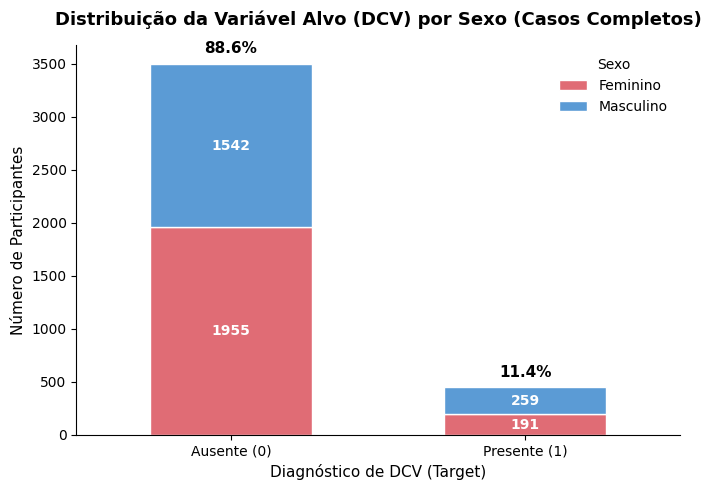

In [6]:
# Distribuição de Doença Cardiovascular (CVD) por Sexo
plot_df = subset_cvd_df.copy()
plot_df['target_label'] = plot_df['target'].map({0: 'Ausente (0)', 1: 'Presente (1)'})
plot_df['gender_label'] = plot_df['gender'].map({1: 'Masculino', 2: 'Feminino'})

counts_df = plot_df.groupby(['target_label', 'gender_label']).size().unstack().reindex(['Ausente (0)', 'Presente (1)'])

fig, ax = plt.subplots(figsize=(7, 5))
counts_df.plot(
    kind='bar', stacked=True, ax=ax,
    color={'Masculino': '#5b9bd5', 'Feminino': '#e06c75'},
    width=0.55, edgecolor='white'
)

for p in ax.patches:
    w, h = p.get_width(), p.get_height()
    x, y = p.get_xy()
    if h > 0:
        ax.text(x + w / 2, y + h / 2, f'{int(h)}', ha='center', va='center', color='white', fontweight='bold', fontsize=10)

totals = counts_df.sum(axis=1)
for i, total in enumerate(totals):
    pct = (total / len(plot_df)) * 100
    ax.text(i, total + totals.max() * 0.02, f"{pct:.1f}%", ha='center', va='bottom', fontweight='bold', fontsize=11)

ax.set_title('Distribuição da Variável Alvo (DCV) por Sexo (Casos Completos)', fontweight='bold', fontsize=13, pad=15)
ax.set_xlabel('Diagnóstico de DCV (Target)', fontsize=11)
ax.set_ylabel('Número de Participantes', fontsize=11)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(title='Sexo', frameon=False)
plt.tight_layout()
plt.show()

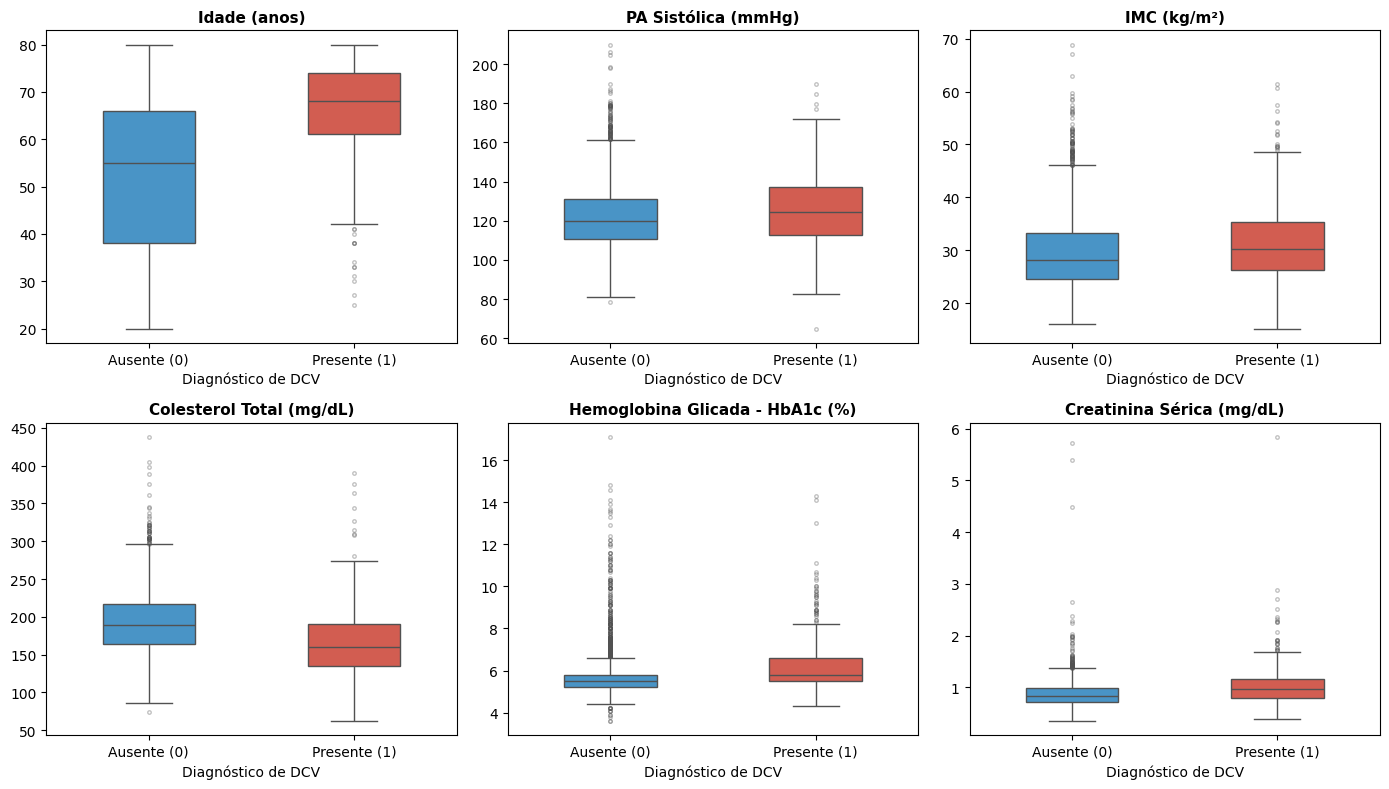

In [7]:
# Boxplots das principais variáveis contínuas por diagnóstico de DCV
box_vars = [
    ('age', 'Idade (anos)'),
    ('sys_bp1', 'PA Sistólica (mmHg)'),
    ('bmi', 'IMC (kg/m²)'),
    ('tc_mgdl', 'Colesterol Total (mg/dL)'),
    ('hba1c', 'Hemoglobina Glicada - HbA1c (%)'),
    ('s_creat_mgdl', 'Creatinina Sérica (mg/dL)')
]

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(14, 8))
axes = axes.flatten()

for i, (col, title) in enumerate(box_vars):
    sns.boxplot(
        data=plot_df, x='target_label', y=col, hue='target_label',
        ax=axes[i], palette={'Ausente (0)': '#3498db', 'Presente (1)': '#e74c3c'},
        legend=False, width=0.45, flierprops={'marker': 'o', 'markersize': 2.5, 'alpha': 0.35}
    )
    axes[i].set_title(title, fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Diagnóstico de DCV', fontsize=10)
    axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

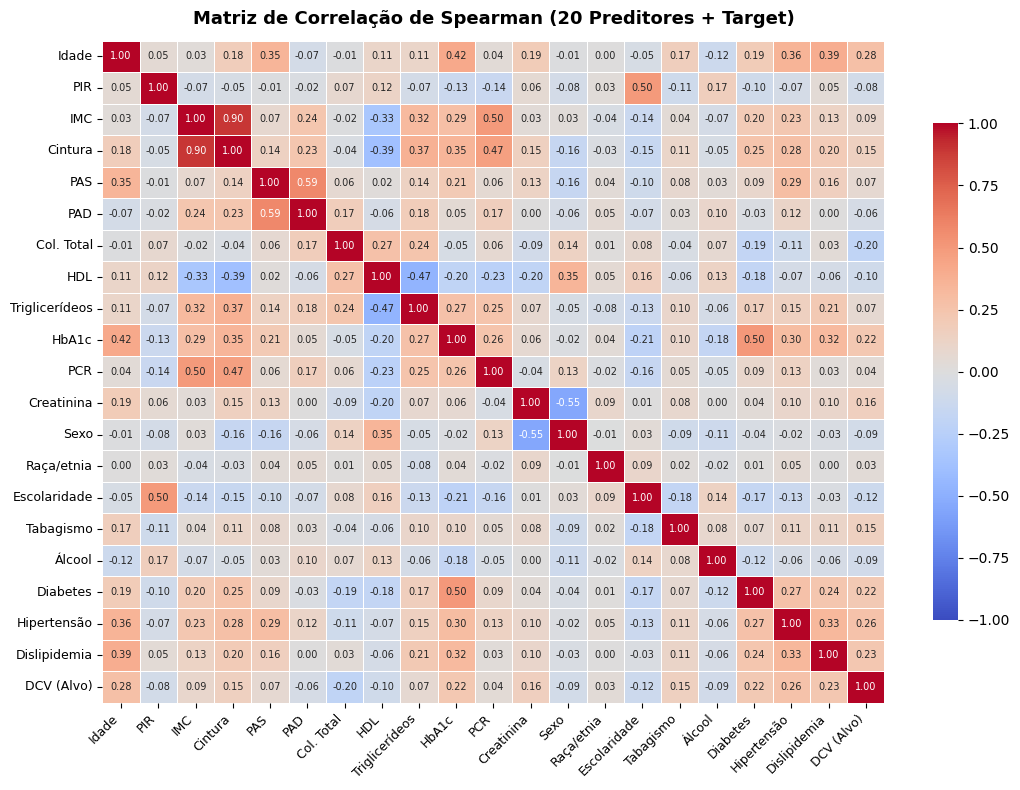

In [8]:
# Matriz de Correlação de Spearman das 20 variáveis preditoras + target
labels_pt = {
    'age': 'Idade', 'gender': 'Sexo', 'race': 'Raça/etnia',
    'education': 'Escolaridade', 'poverty_ratio': 'PIR',
    'bmi': 'IMC', 'waist_circ_cm': 'Cintura',
    'sys_bp1': 'PAS', 'dia_bp1': 'PAD',
    'tc_mgdl': 'Col. Total', 'hdl_mgdl': 'HDL', 'tg_mgdl': 'Triglicerídeos',
    'hba1c': 'HbA1c', 'crp_mgl': 'PCR', 's_creat_mgdl': 'Creatinina',
    'smk_cat': 'Tabagismo', 'alc_cat': 'Álcool',
    'diab_diag': 'Diabetes', 'high_bp_diag': 'Hipertensão',
    'high_chol_diag': 'Dislipidemia', 'target': 'DCV (Alvo)'
}

corr = subset_cvd_df.corr(method='spearman').rename(index=labels_pt, columns=labels_pt)

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(
    corr, annot=True, fmt='.2f', annot_kws={'size': 7},
    cmap='coolwarm', vmin=-1, vmax=1, center=0,
    linewidths=0.4, linecolor='white', cbar_kws={'shrink': 0.75}, ax=ax
)
ax.set_title('Matriz de Correlação de Spearman (20 Preditores + Target)', fontsize=13, fontweight='bold', pad=12)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.savefig('figuras/matriz-de-correlacao.png', dpi=300, bbox_inches='tight')
plt.show()

## 5. Divisão Estratificada, Pré-Processamento e Pipeline com Over/Under-Sampling
Com os registros completos (`dropna()`), o pipeline não realiza imputação de dados e aplica diretamente:
- **Divisão Treino/Teste:** Separação estratificada na proporção **70% treinamento / 30% teste** (`train_test_split(..., test_size=0.30, stratify=y)`).
- **Transformação de Atributos (`ColumnTransformer`):**
  - **Atributos Contínuos (12):** Padronização (`StandardScaler()`).
  - **Atributos Categóricos (8):** Codificação *one-hot* (`OneHotEncoder(handle_unknown='ignore', sparse_output=False)`).
- **Reamostragem (`SMOTE` vs. `RandomUnderSampler`):** A etapa `sampler` do `ImbPipeline` testa tanto sobreamostragem sintética da classe minoritária (**`SMOTE`**) quanto subamostragem aleatória da classe majoritária (**`RandomUnderSampler`**), aplicada **exclusivamente nos dados de treinamento de cada partição** da validação cruzada.

In [9]:
X = subset_cvd_df[predictor_cols].copy()
y = subset_cvd_df['target'].copy()

X_train_cv, X_test_final, y_train_cv, y_test_final = train_test_split(
    X, y, test_size=0.30, random_state=FIXED_RANDOM_STATE, stratify=y
)

print(f"Conjunto de Treinamento (70%): {X_train_cv.shape[0]} amostras | Positivos: {(y_train_cv == 1).sum()} ({y_train_cv.mean()*100:.2f}%)")
print(f"Conjunto de Teste (30%):       {X_test_final.shape[0]} amostras | Positivos: {(y_test_final == 1).sum()} ({y_test_final.mean()*100:.2f}%)")

# ColumnTransformer sem imputação (dados já completos via dropna)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), continuous_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

# Candidatos de reamostragem (Over-sampling via SMOTE e Under-sampling via RandomUnderSampler)
samplers = [
    SMOTE(random_state=FIXED_RANDOM_STATE),
    RandomUnderSampler(random_state=FIXED_RANDOM_STATE)
]

# Pipelines completos (Pré-processamento -> Sampler [SMOTE / Undersampling] -> Classificador)
pipelines = {
    "Logistic Regression": ImbPipeline([
        ('preprocessor', preprocessor),
        ('sampler', SMOTE(random_state=FIXED_RANDOM_STATE)),
        ('model', LogisticRegression(max_iter=1000, solver='liblinear', random_state=FIXED_RANDOM_STATE))
    ]),
    "KNN": ImbPipeline([
        ('preprocessor', preprocessor),
        ('sampler', SMOTE(random_state=FIXED_RANDOM_STATE)),
        ('model', KNeighborsClassifier())
    ]),
    "Decision Tree": ImbPipeline([
        ('preprocessor', preprocessor),
        ('sampler', SMOTE(random_state=FIXED_RANDOM_STATE)),
        ('model', DecisionTreeClassifier(random_state=FIXED_RANDOM_STATE))
    ]),
    "Random Forest": ImbPipeline([
        ('preprocessor', preprocessor),
        ('sampler', SMOTE(random_state=FIXED_RANDOM_STATE)),
        ('model', RandomForestClassifier(random_state=FIXED_RANDOM_STATE, n_jobs=-1))
    ]),
    "XGBoost": ImbPipeline([
        ('preprocessor', preprocessor),
        ('sampler', SMOTE(random_state=FIXED_RANDOM_STATE)),
        ('model', XGBClassifier(tree_method='hist', eval_metric='logloss', random_state=FIXED_RANDOM_STATE, n_jobs=-1))
    ])
}

Conjunto de Treinamento (70%): 2762 amostras | Positivos: 315 (11.40%)
Conjunto de Teste (30%):       1185 amostras | Positivos: 135 (11.39%)


## 6. Validação Cruzada Estratificada ($k = 5$) e Otimização (Hiperparâmetros + Estratégia de Reamostragem)
A otimização via `RandomizedSearchCV` com validação cruzada estratificada de 5 partições (`StratifiedKFold(n_splits=5)`) seleciona simultaneamente a melhor técnica de balanceamento (`SMOTE` vs. `RandomUnderSampler`) e os melhores hiperparâmetros de cada modelo maximizando o **F2-Score** ($eta = 2$).

In [10]:
param_distributions = {
    "Logistic Regression": {
        'sampler': samplers,
        'model__C': loguniform(0.01, 10.0),
        'model__penalty': ['l1', 'l2']
    },
    "KNN": {
        'sampler': samplers,
        'model__n_neighbors': randint(3, 31),
        'model__weights': ['uniform', 'distance'],
        'model__p': [1, 2]
    },
    "Decision Tree": {
        'sampler': samplers,
        'model__max_depth': randint(3, 16),
        'model__min_samples_split': randint(2, 20),
        'model__min_samples_leaf': randint(2, 15),
        'model__criterion': ['gini', 'entropy']
    },
    "Random Forest": {
        'sampler': samplers,
        'model__n_estimators': randint(100, 400),
        'model__max_depth': randint(4, 16),
        'model__min_samples_split': randint(2, 20),
        'model__min_samples_leaf': randint(2, 12),
        'model__max_features': ['sqrt', 'log2']
    },
    "XGBoost": {
        'sampler': samplers,
        'model__n_estimators': randint(100, 400),
        'model__learning_rate': loguniform(0.01, 0.15),
        'model__max_depth': randint(2, 8),
        'model__subsample': uniform(0.6, 0.4),
        'model__colsample_bytree': uniform(0.6, 0.4)
    }
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=FIXED_RANDOM_STATE)
f2_scorer = make_scorer(fbeta_score, beta=2)

best_models = {}
search_results = []

for name, pipeline in pipelines.items():
    print(f"=== Otimizando: {name} ===")
    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_distributions[name],
        n_iter=20,
        scoring=f2_scorer,
        cv=cv_strategy,
        random_state=FIXED_RANDOM_STATE,
        n_jobs=-1,
        refit=True
    )
    search.fit(X_train_cv, y_train_cv)
    best_models[name] = search.best_estimator_

    chosen_sampler = type(search.best_params_['sampler']).__name__
    model_params = {k.replace('model__', ''): v for k, v in search.best_params_.items() if k != 'sampler'}

    search_results.append({
        "Modelo": name,
        "Reamostragem Selecionada": chosen_sampler,
        "Melhor F2 (CV 5-fold)": round(search.best_score_, 4),
        "Melhores Hiperparâmetros": model_params
    })
    print(f"  -> Melhor F2 (CV): {search.best_score_:.4f} | Sampler: {chosen_sampler} | Params: {model_params}")

df_search_results = pd.DataFrame(search_results).set_index("Modelo")
display(df_search_results)

=== Otimizando: Logistic Regression ===


  -> Melhor F2 (CV): 0.5990 | Sampler: SMOTE | Params: {'C': 0.014936568554617643, 'penalty': 'l2'}
=== Otimizando: KNN ===


  -> Melhor F2 (CV): 0.5615 | Sampler: RandomUnderSampler | Params: {'n_neighbors': 12, 'p': 2, 'weights': 'distance'}
=== Otimizando: Decision Tree ===


  -> Melhor F2 (CV): 0.5231 | Sampler: RandomUnderSampler | Params: {'criterion': 'entropy', 'max_depth': 11, 'min_samples_leaf': 11, 'min_samples_split': 3}
=== Otimizando: Random Forest ===


  -> Melhor F2 (CV): 0.5944 | Sampler: RandomUnderSampler | Params: {'max_depth': 12, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'min_samples_split': 5, 'n_estimators': 188}
=== Otimizando: XGBoost ===


  -> Melhor F2 (CV): 0.5905 | Sampler: RandomUnderSampler | Params: {'colsample_bytree': 0.7564242430292963, 'learning_rate': 0.01638046665239941, 'max_depth': 5, 'n_estimators': 101, 'subsample': 0.7700623497964979}


,Reamostragem Selecionada,Melhor F2 (CV 5-fold),Melhores Hiperparâmetros
Modelo,,,
Logistic Regression,SMOTE,0.5990,"{'C': 0.014936568554617643, 'penalty': 'l2'}"
KNN,RandomUnderSampler,0.5615,"{'n_neighbors': 12, 'p': 2, 'weights': 'distan..."
Decision Tree,RandomUnderSampler,0.5231,"{'criterion': 'entropy', 'max_depth': 11, 'min..."
Random Forest,RandomUnderSampler,0.5944,"{'max_depth': 12, 'max_features': 'sqrt', 'min..."
XGBoost,RandomUnderSampler,0.5905,"{'colsample_bytree': 0.7564242430292963, 'lear..."


## 7. Avaliação Final no Conjunto de Teste Independente (Holdout)
Os melhores modelos selecionados na validação cruzada são avaliados no conjunto de teste reservado (30%), comparando **Acurácia, Precisão, Recall, F1-Score, F2-Score e AUC-ROC**, além das **Matrizes de Confusão** e **Curvas ROC** sobrepostas.

Desempenho Final no Conjunto de Teste (Holdout 30%):


,Sampler,Accuracy,Precision,Recall,F1-Score,F2-Score,AUC-ROC
Model,,,,,,,
Logistic Regression,SMOTE,0.7502,0.2770,0.7407,0.4032,0.5549,0.8267
KNN,RandomUnderSampler,0.7342,0.2554,0.6963,0.3738,0.5176,0.7930
Decision Tree,RandomUnderSampler,0.7392,0.2636,0.7185,0.3857,0.5341,0.7688
Random Forest,RandomUnderSampler,0.7249,0.2607,0.7704,0.3895,0.5538,0.8256
XGBoost,RandomUnderSampler,0.7333,0.2685,0.7778,0.3992,0.5639,0.8262


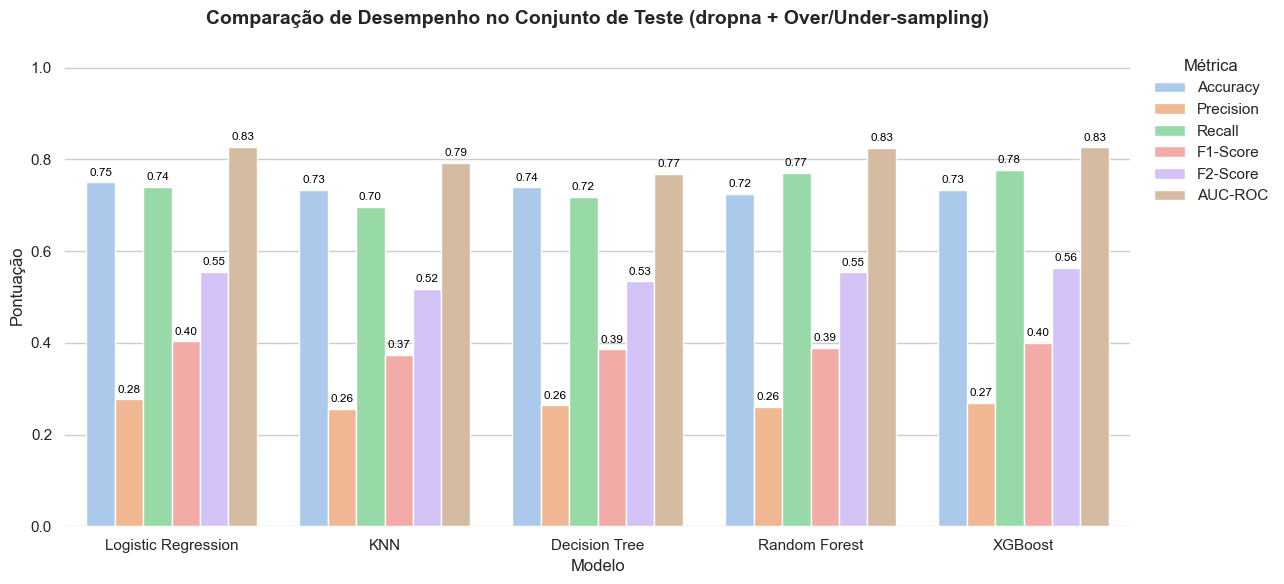

In [11]:
results = []
cnf_matrices = []
roc_values = []

for name, model in best_models.items():
    y_pred_final = model.predict(X_test_final)
    y_prob_final = model.predict_proba(X_test_final)[:, 1]

    roc_auc = roc_auc_score(y_test_final, y_prob_final)
    fpr, tpr, thresholds = roc_curve(y_test_final, y_prob_final)

    roc_values.append({"Model": name, "FPR": fpr, "TPR": tpr, "AUC": roc_auc})
    cnf_matrices.append({"Model": name, "Confusion Matrix": confusion_matrix(y_test_final, y_pred_final)})
    results.append({
        "Model": name,
        "Sampler": type(model.named_steps['sampler']).__name__,
        "Accuracy": accuracy_score(y_test_final, y_pred_final),
        "Precision": precision_score(y_test_final, y_pred_final),
        "Recall": recall_score(y_test_final, y_pred_final),
        "F1-Score": f1_score(y_test_final, y_pred_final),
        "F2-Score": fbeta_score(y_test_final, y_pred_final, beta=2),
        "AUC-ROC": roc_auc
    })

df_teste_final = pd.DataFrame(results).set_index("Model")
print("Desempenho Final no Conjunto de Teste (Holdout 30%):")
display(df_teste_final.round(4))

# Gráfico comparativo das métricas no conjunto de teste
df_melted = (
    df_teste_final[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'F2-Score', 'AUC-ROC']]
    .reset_index()
    .melt(id_vars="Model", var_name="Métrica", value_name="Pontuação")
)

plt.figure(figsize=(13, 6))
sns.set_theme(style="whitegrid", palette="pastel")
ax = sns.barplot(data=df_melted, x="Model", y="Pontuação", hue="Métrica")

plt.title('Comparação de Desempenho no Conjunto de Teste (dropna + Over/Under-sampling)', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Pontuação', fontsize=12)
plt.xlabel('Modelo', fontsize=12)
plt.ylim(0, 1.05)
plt.xticks(rotation=0, fontsize=11)
plt.legend(title='Métrica', loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False)
sns.despine(left=True, bottom=True)

for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(
            f'{h:.2f}',
            (p.get_x() + p.get_width() / 2., h),
            ha='center', va='center',
            xytext=(0, 7), textcoords='offset points',
            fontsize=8.5, color='black'
        )

plt.tight_layout()
plt.savefig('figuras/metricas-teste-holdout.png', dpi=300, bbox_inches='tight')
plt.show()

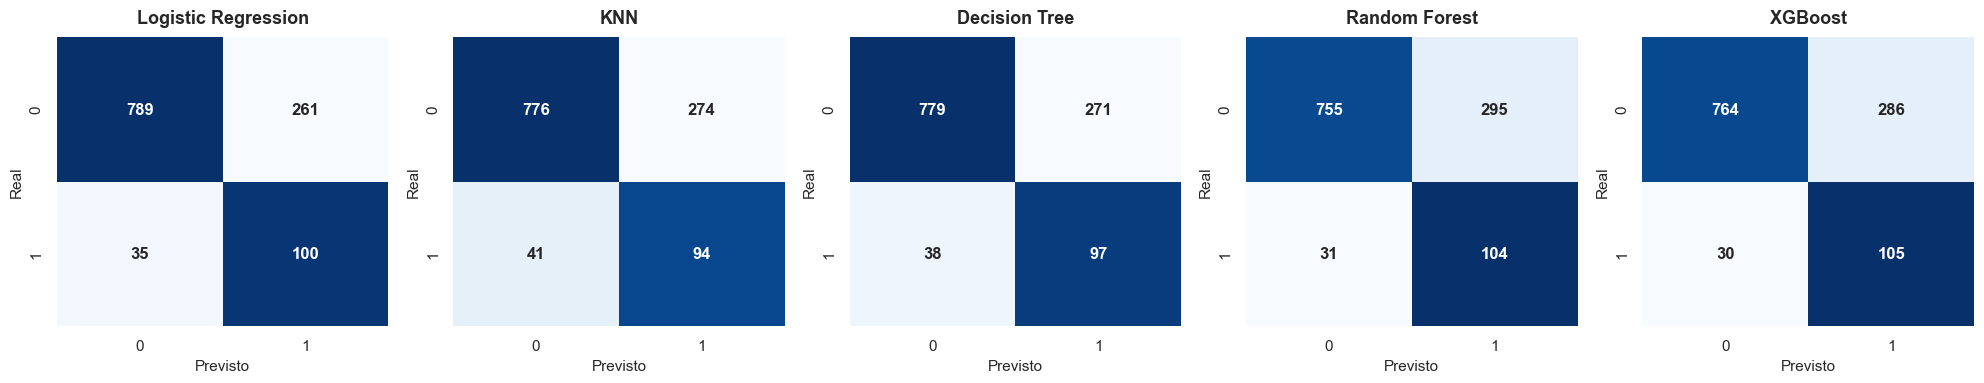

In [12]:
# Matrizes de Confusão Normalizadas para os 5 Modelos
fig, axes = plt.subplots(nrows=1, ncols=5, figsize=(20, 4))
axes = axes.flatten()

for i, item in enumerate(cnf_matrices):
    cm = np.array(item['Confusion Matrix'])
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    sns.heatmap(
        cm_norm, annot=cm, cmap="Blues", fmt='g', cbar=False,
        ax=axes[i], annot_kws={"size": 12, "weight": "bold"}
    )
    axes[i].set_title(item['Model'], fontsize=13, fontweight='bold', pad=10)
    axes[i].set_xlabel('Previsto', fontsize=11)
    axes[i].set_ylabel('Real', fontsize=11)

plt.tight_layout()
plt.savefig('figuras/matrizes-confusao.png', dpi=300, bbox_inches='tight')
plt.show()

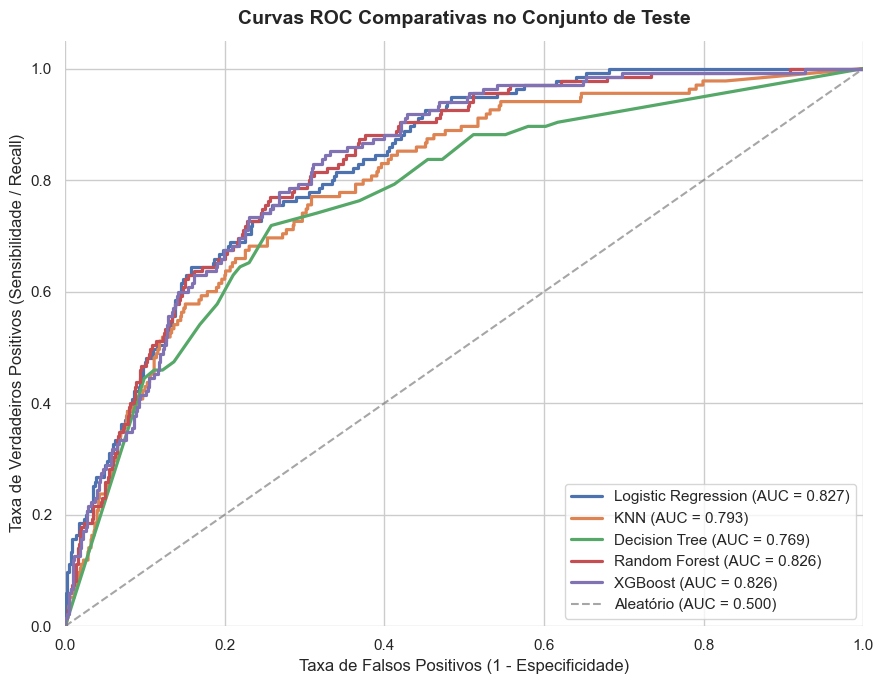

In [13]:
# Curvas ROC Sobrepostas no Conjunto de Teste
plt.figure(figsize=(9, 7))
sns.set_theme(style="whitegrid", palette="deep")

for curva in roc_values:
    plt.plot(
        curva["FPR"], curva["TPR"],
        linewidth=2.3,
        label=f"{curva['Model']} (AUC = {curva['AUC']:.3f})"
    )

plt.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=1.5, alpha=0.7, label='Aleatório (AUC = 0.500)')
plt.title('Curvas ROC Comparativas no Conjunto de Teste', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Taxa de Falsos Positivos (1 - Especificidade)', fontsize=12)
plt.ylabel('Taxa de Verdadeiros Positivos (Sensibilidade / Recall)', fontsize=12)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.legend(loc="lower right", fontsize=11, frameon=True)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.savefig('figuras/auc-roc-baseline.png', dpi=300, bbox_inches='tight')
plt.show()